# Homework 6

## 1. Tree-Based Methods

### (a) Load the APS Failure Dataset

I use the training and test sets provided with the assignment.
There are 170 numerical features and one class column.
Missing values are marked as "na".

In [1]:
from pathlib import Path

data_dir = Path("data")

data_files = [
    "aps_failure_training_set.csv",
    "aps_failure_test_set.csv"
]

missing_files = [
    filename
    for filename in data_files
    if not (data_dir / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Put the APS CSV files in the data folder. Missing files: "
        + ", ".join(missing_files)
    )

print("Working directory:", Path.cwd())
print("Data folder:", data_dir.resolve())

for filename in data_files:
    print(filename, "exists:", (data_dir / filename).is_file())

Working directory: C:\Users\19098\DSCI-552\Homework6
Data folder: C:\Users\19098\DSCI-552\Homework6\data
aps_failure_training_set.csv exists: True
aps_failure_test_set.csv exists: True


In [2]:
import pandas as pd

train_data = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_data = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)
print("Number of features:", train_data.shape[1] - 1)

print("\nTraining class counts:")
print(train_data["class"].value_counts())

print("\nTest class counts:")
print(test_data["class"].value_counts())

print(
    "\nMissing values in training data:",
    train_data.isna().sum().sum()
)

print(
    "Missing values in test data:",
    test_data.isna().sum().sum()
)

assert train_data.shape == (60000, 171)
assert test_data.shape == (16000, 171)
assert train_data.columns.equals(test_data.columns)
assert train_data["class"].notna().all()
assert test_data["class"].notna().all()

print("\nAll checks passed.")

display(train_data.head())

Training data shape: (60000, 171)
Test data shape: (16000, 171)
Number of features: 170

Training class counts:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test class counts:
class
neg    15625
pos      375
Name: count, dtype: int64

Missing values in training data: 850015
Missing values in test data: 228680

All checks passed.


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Missing Values

Common methods for handling missing values include:

- Mean or median imputation: fill missing values with a column's mean or median.
- KNN imputation: use similar observations to estimate missing values.
- Model-based imputation: use other features to predict missing values.
- Multiple imputation: create several completed data sets.

I use median imputation. The median is less affected by extreme
values than the mean. This method is also simple and fast.

I keep all 170 features. I fit the imputer on the training set
and use the same medians to fill missing values in the test set.
For cross-validation, I will fit a new imputer inside each fold.

Reference:
https://scikit-learn.org/stable/modules/impute.html

In [3]:
X_train_raw = train_data.drop(columns="class").copy()
X_test_raw = test_data.drop(columns="class").copy()

label_map = {"neg": 0, "pos": 1}

y_train = train_data["class"].map(label_map)
y_test = test_data["class"].map(label_map)

assert y_train.notna().all()
assert y_test.notna().all()

y_train = y_train.astype(int)
y_test = y_test.astype(int)

print("Training features:", X_train_raw.shape)
print("Test features:", X_test_raw.shape)

missing_summary = pd.DataFrame({
    "missing_count": X_train_raw.isna().sum(),
    "missing_percent": X_train_raw.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

print("\nTraining features with the most missing values:")
display(missing_summary.head(10).round(2))

print(
    "Fully missing training features:",
    int(X_train_raw.isna().all().sum())
)

Training features: (60000, 170)
Test features: (16000, 170)

Training features with the most missing values:


,missing_count,missing_percent
br_000,49264,82.11
bq_000,48722,81.20
bp_000,47740,79.57
bo_000,46333,77.22
ab_000,46329,77.22
cr_000,46329,77.22
bn_000,44009,73.35
bm_000,39549,65.92
bl_000,27277,45.46
bk_000,23034,38.39


Fully missing training features: 0


In [4]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Training features after imputation:", X_train.shape)
print("Test features after imputation:", X_test.shape)

print(
    "Missing values in training features:",
    X_train.isna().sum().sum()
)

print(
    "Missing values in test features:",
    X_test.isna().sum().sum()
)

assert X_train.shape == (60000, 170)
assert X_test.shape == (16000, 170)
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

print("\nAll imputation checks passed.")

Training features after imputation: (60000, 170)
Test features after imputation: (16000, 170)
Missing values in training features: 0
Missing values in test features: 0

All imputation checks passed.


#### (ii) Coefficient of Variation

For each feature, I calculate the coefficient of variation:

$$
CV = \frac{s}{m}
$$

Here, s is the sample standard deviation, and m is the sample mean.

I use the imputed training data before standardization.
A larger CV means more variation compared with the feature's mean.
It does not necessarily mean that the feature is better for prediction.

In [5]:
import numpy as np

feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

feature_cv = feature_stds / feature_means.replace(0, np.nan)

cv_summary = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "CV": feature_cv
})

cv_summary.index.name = "feature"

cv_summary = cv_summary.sort_values(
    "CV",
    ascending=False
)

constant_features = feature_stds.index[
    feature_stds.eq(0)
].tolist()

print("Number of features:", len(cv_summary))
print("Features with zero mean:", int(feature_means.eq(0).sum()))
print("Constant features:", constant_features)

assert len(cv_summary) == 170
assert np.isfinite(cv_summary["CV"].to_numpy()).all()

with pd.option_context("display.max_rows", 200):
    display(cv_summary.round(4))

Number of features: 170
Features with zero mean: 0
Constant features: ['cd_000']


,mean,sample_std,CV
feature,,,
cf_000,1.431075e+05,3.504525e+07,244.8875
co_000,1.433300e+05,3.504525e+07,244.5074
ad_000,1.434383e+05,3.504525e+07,244.3228
cs_009,7.705097e+02,1.833278e+05,237.9306
dh_000,4.392641e+03,5.412441e+05,123.2161
dj_000,3.727130e+01,4.379166e+03,117.4942
ag_000,2.191577e+02,2.036364e+04,92.9178
as_000,1.254079e+02,1.095219e+04,87.3325
ay_009,1.149620e+03,9.741156e+04,84.7337


#### (iii) Correlation Matrix

I calculate Pearson correlations using the imputed training data.

Values close to 1 show a strong positive linear relationship.
Values close to -1 show a strong negative linear relationship.
Values close to 0 show a weak linear relationship.

The feature cd_000 is constant in the training data.
Its correlations are undefined, so they appear as blank cells.

Correlation matrix shape: (170, 170)


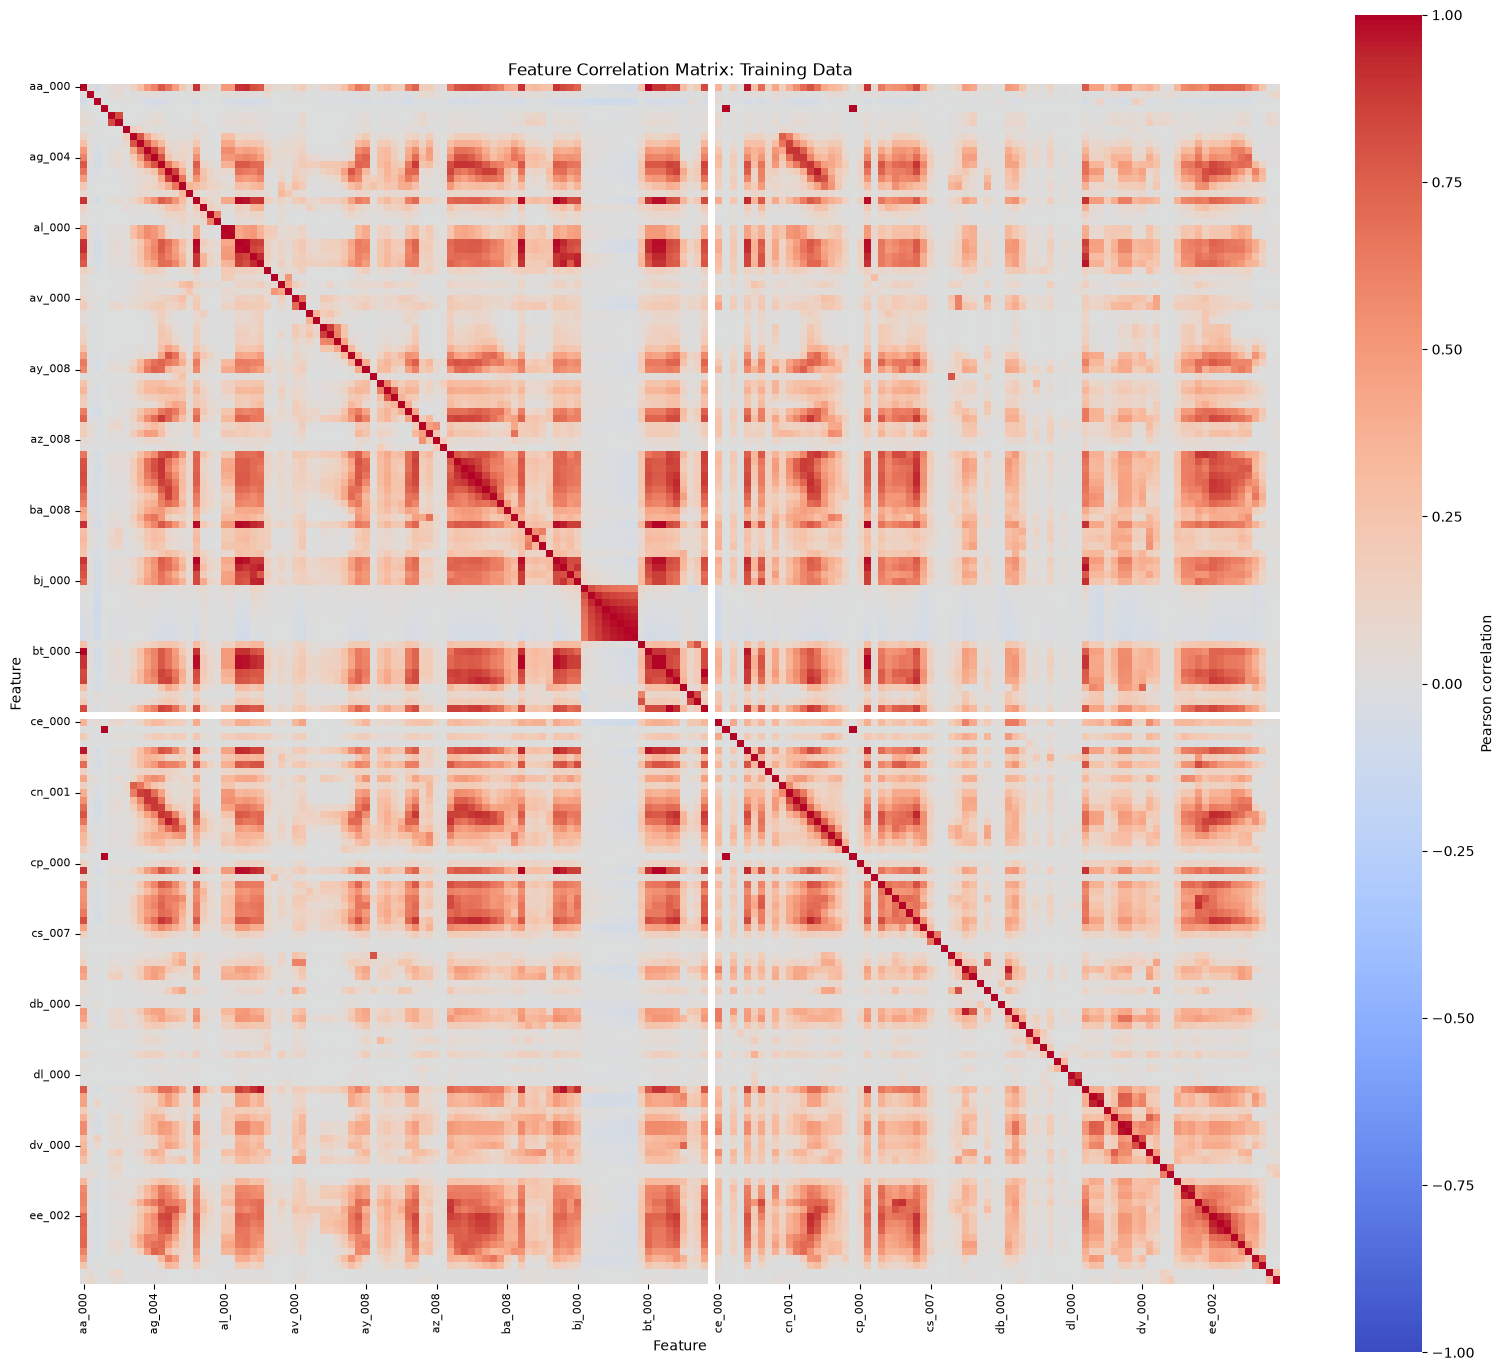

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = X_train.corr()

print("Correlation matrix shape:", correlation_matrix.shape)

assert correlation_matrix.shape == (170, 170)

plt.figure(figsize=(16, 14))

sns.heatmap(
    correlation_matrix,
    mask=correlation_matrix.isna(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=10,
    yticklabels=10,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Feature Correlation Matrix: Training Data")
plt.xlabel("Feature")
plt.ylabel("Feature")

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

#### (iv) Features with the Highest CV

I select the 13 features with the highest CV because
the floor of the square root of 170 is 13.

I use the training data to make scatter plots and box plots.
The colors show the negative and positive classes.

For these plots, I use log(1 + x) because some values are very large.
This transformation is only used for visualization.

I will still use all 170 features for the models.

In [7]:
n_plot_features = int(np.sqrt(X_train.shape[1]))

top_features = cv_summary.head(
    n_plot_features
).index.tolist()

print("Number of selected features:", n_plot_features)
display(cv_summary.loc[top_features].round(4))

assert n_plot_features == 13

selected_plot_data = X_train[top_features].copy()

assert (selected_plot_data >= 0).all().all()

plot_data = np.log1p(selected_plot_data)

plot_data["Class"] = y_train.map({
    0: "neg",
    1: "pos"
})

plot_data = plot_data.sort_values(
    "Class",
    kind="stable"
)

print("Training instances used in plots:", len(plot_data))
print("\nClass counts:")
print(plot_data["Class"].value_counts())

Number of selected features: 13


,mean,sample_std,CV
feature,,,
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337


Training instances used in plots: 60000

Class counts:
Class
neg    59000
pos     1000
Name: count, dtype: int64


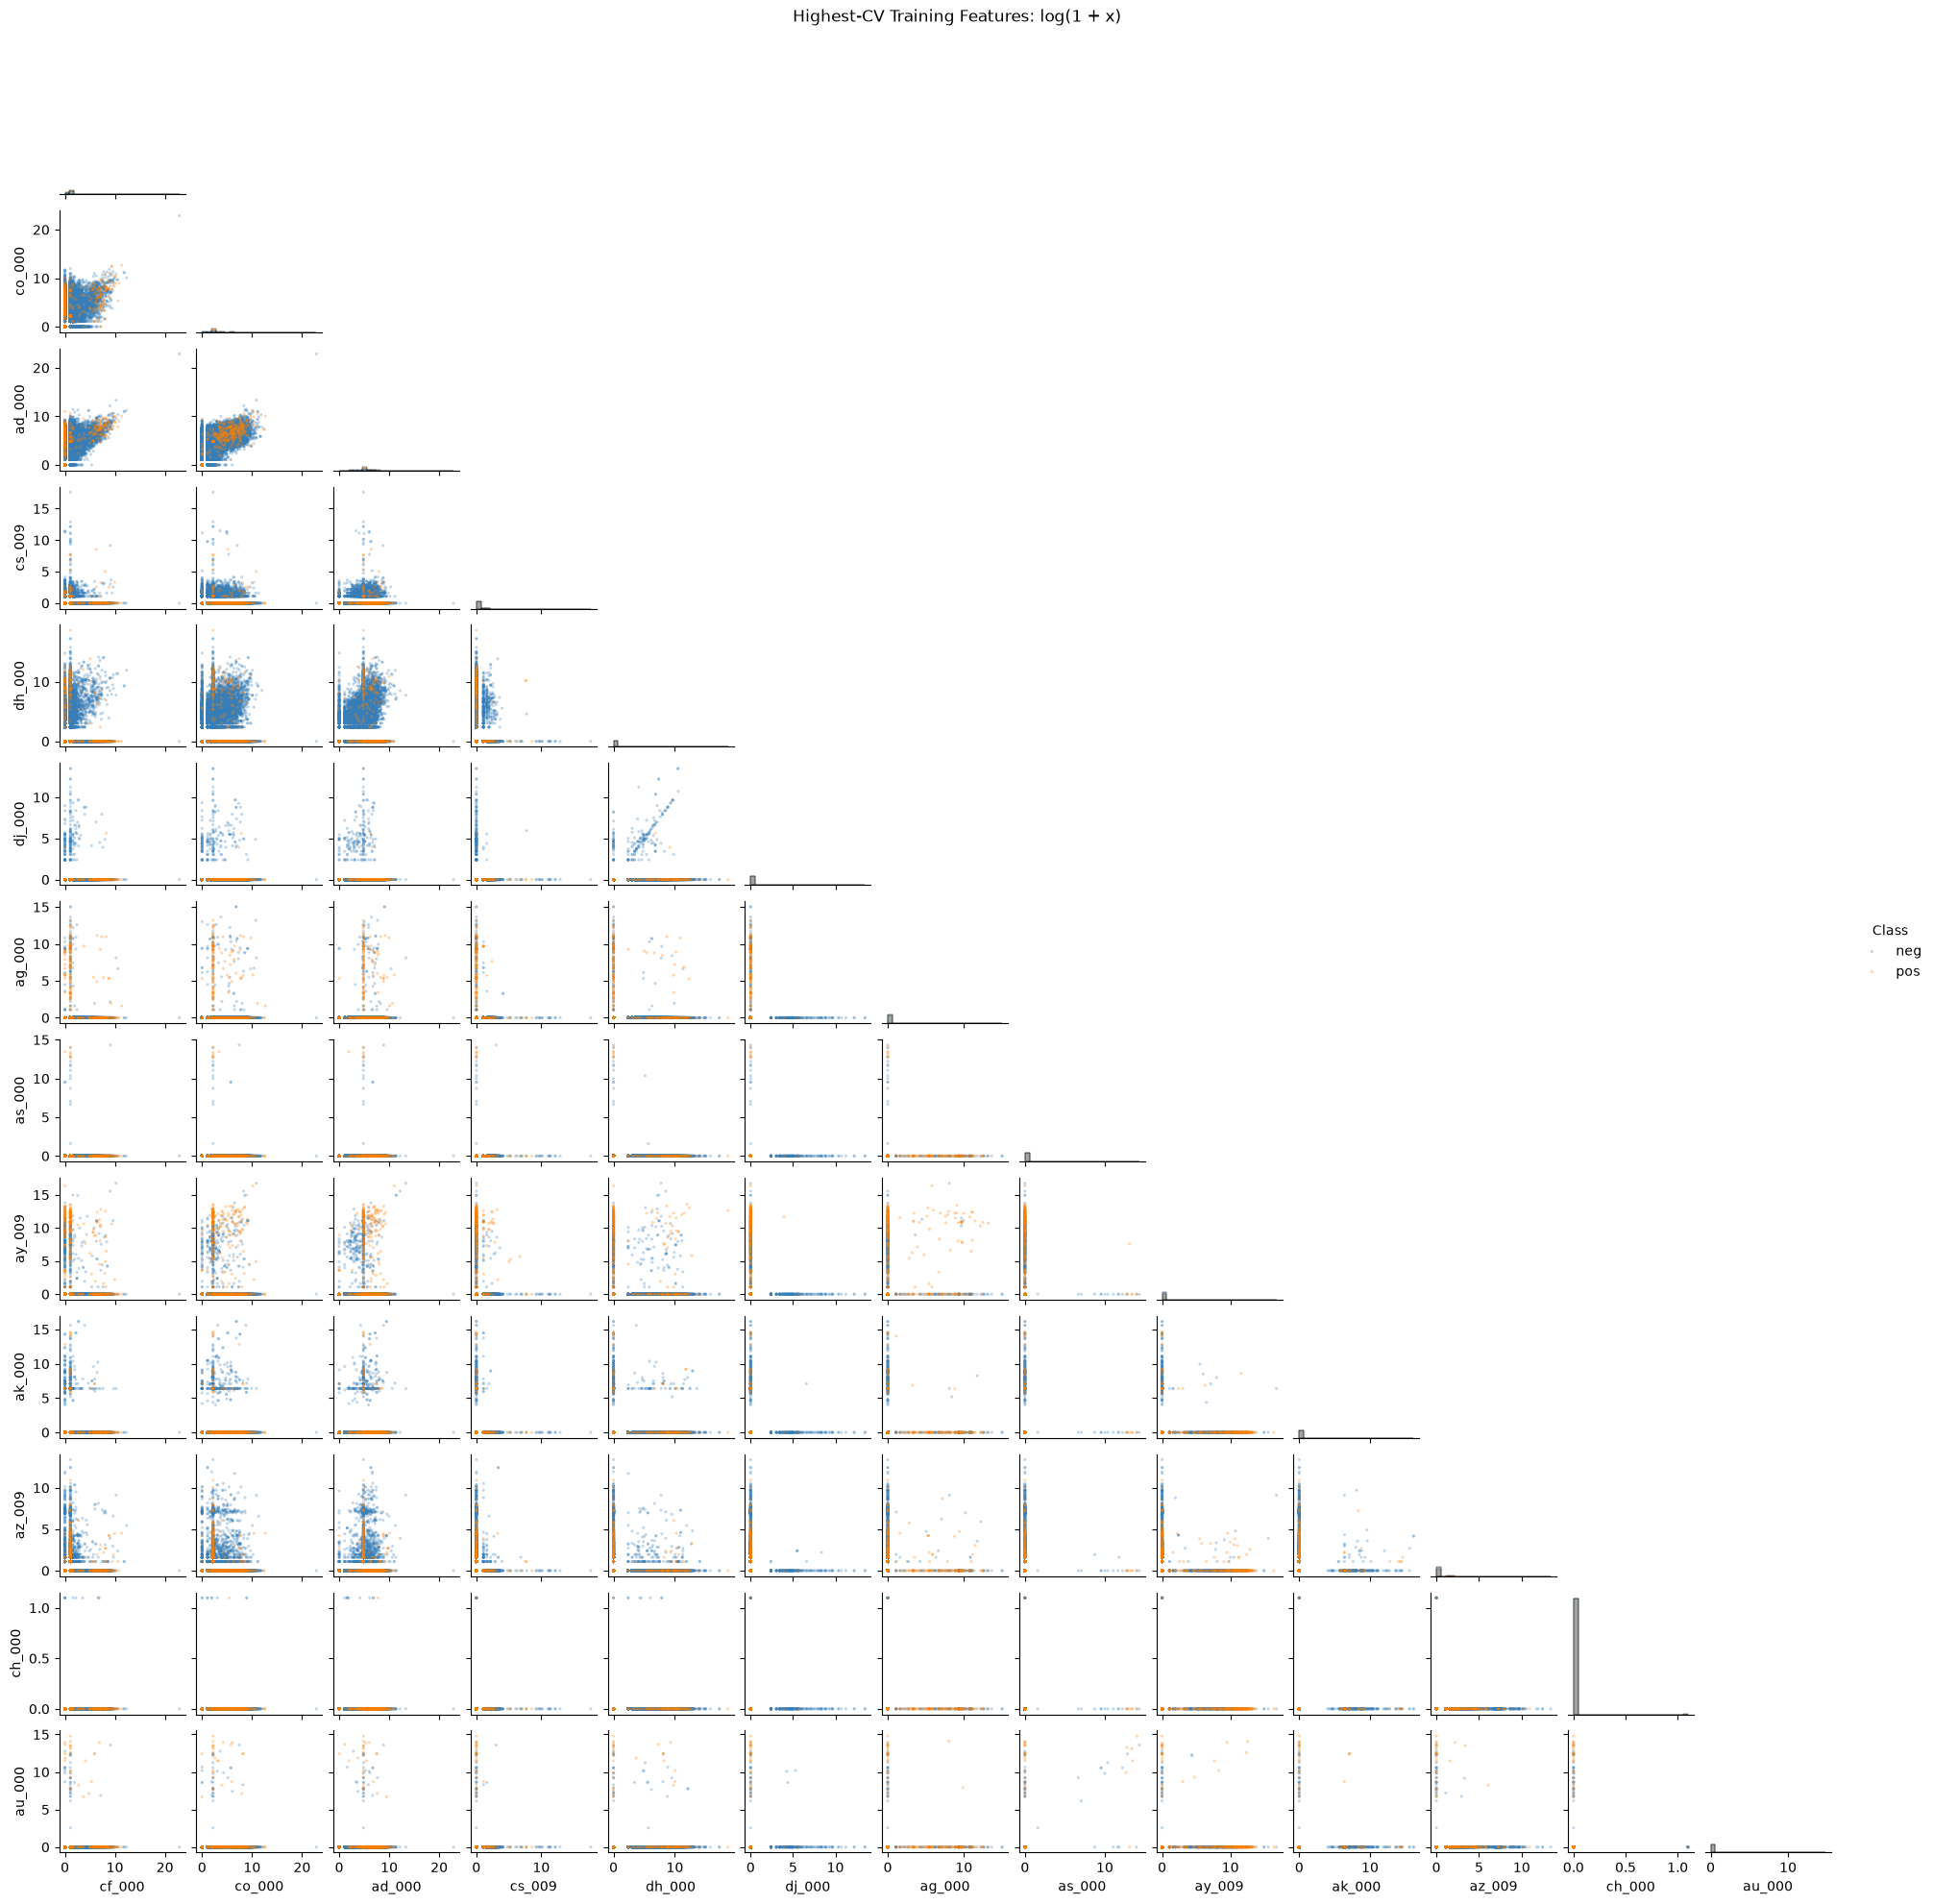

In [8]:
class_colors = {
    "neg": "#377EB8",
    "pos": "#FF7F00"
}

g = sns.pairplot(
    data=plot_data,
    vars=top_features,
    hue="Class",
    hue_order=["neg", "pos"],
    palette=class_colors,
    diag_kind="hist",
    corner=True,
    height=1.5,
    plot_kws={
        "s": 5,
        "alpha": 0.3,
        "linewidth": 0,
        "rasterized": True
    },
    diag_kws={
        "bins": 25,
        "stat": "density",
        "common_norm": False,
        "alpha": 0.45
    }
)

g.figure.suptitle(
    "Highest-CV Training Features: log(1 + x)",
    y=1.02
)

plt.show()

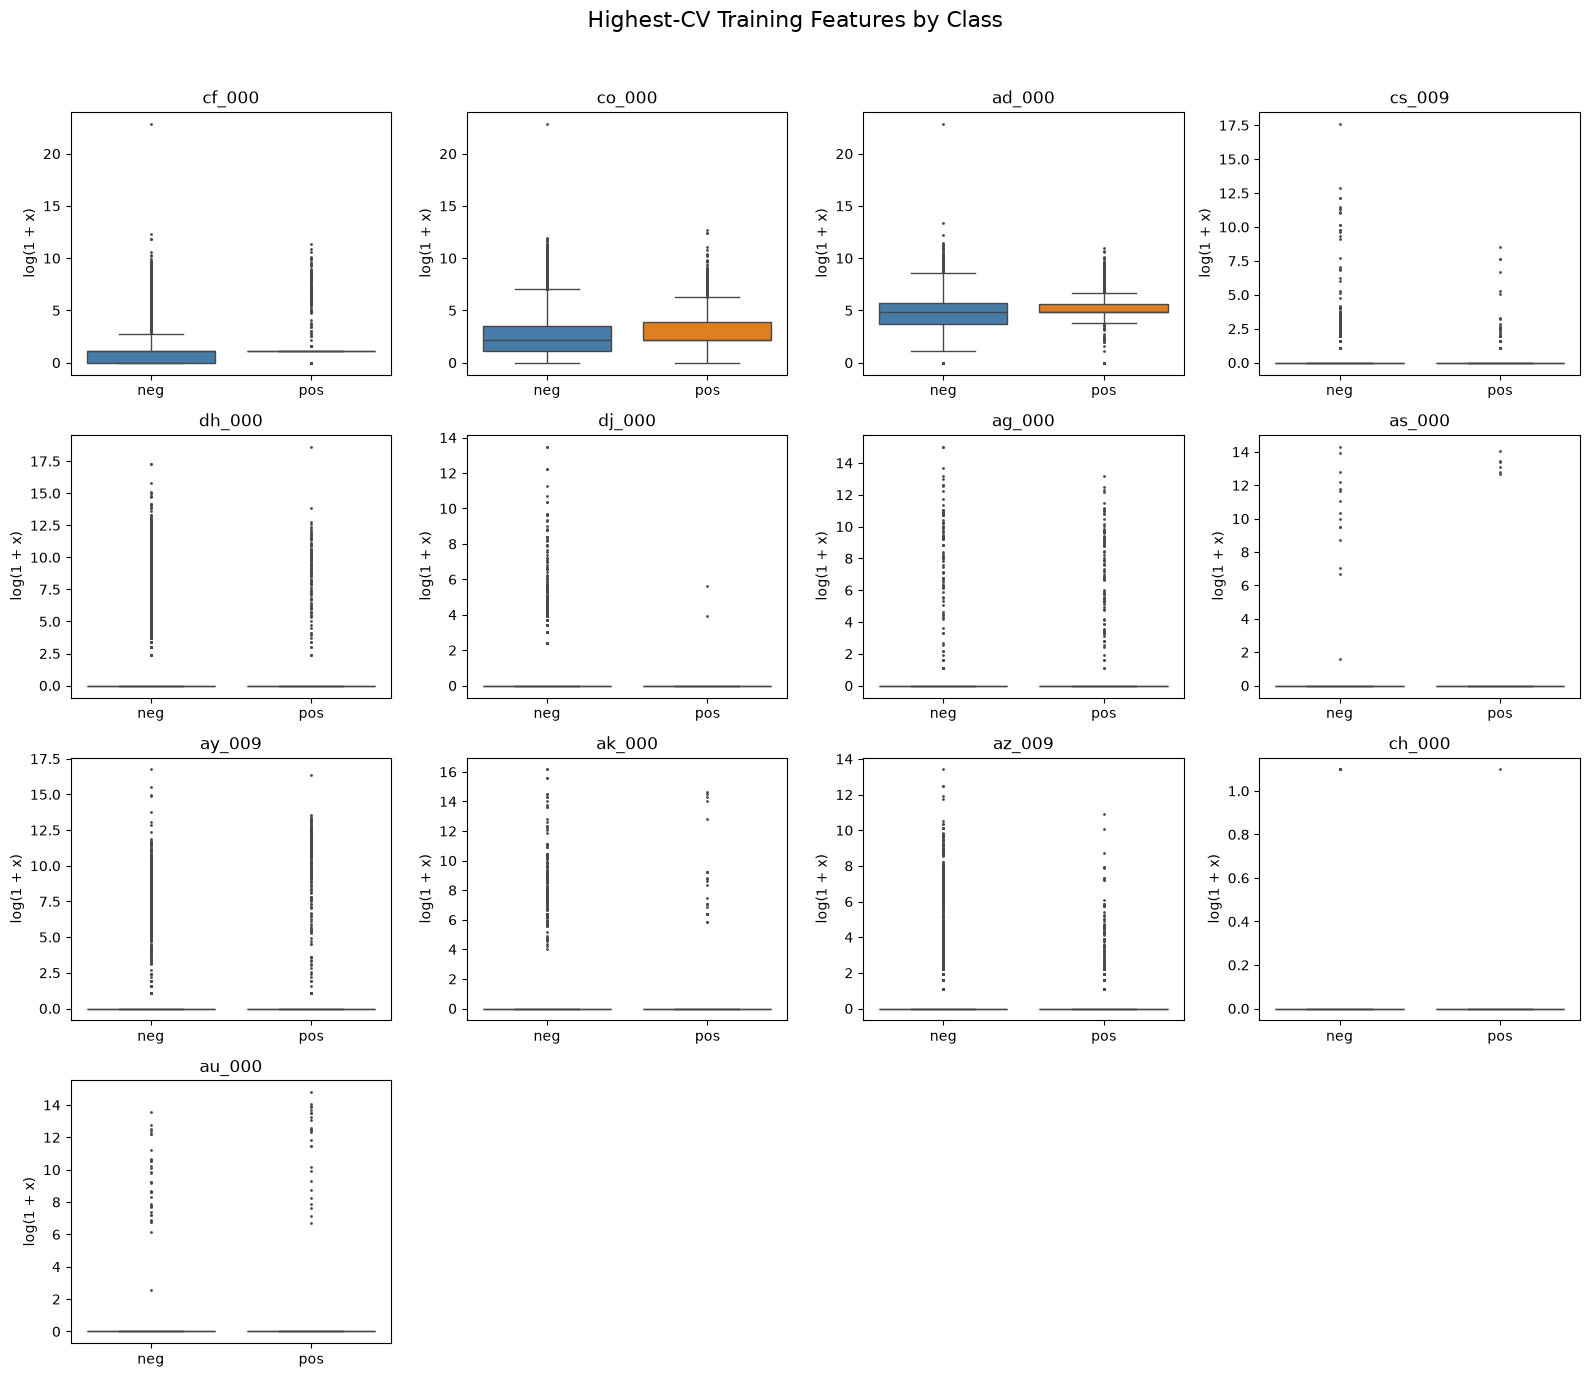

In [9]:
fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 14)
)

axes = axes.ravel()

for ax, feature in zip(axes, top_features):
    sns.boxplot(
        data=plot_data,
        x="Class",
        y=feature,
        order=["neg", "pos"],
        hue="Class",
        hue_order=["neg", "pos"],
        palette=class_colors,
        dodge=False,
        showfliers=True,
        fliersize=1,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + x)")

    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

for ax in axes[len(top_features):]:
    ax.remove()

fig.suptitle(
    "Highest-CV Training Features by Class",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

The plots show many zero values and some extreme values.
Several box plots are flat because many observations have the same value.

For features such as ag_000 and ay_009, the positive class has
more nonzero values. However, the two classes still overlap.

Can't determine statistical significance from scatter plots alone.
A high CV only shows large variation compared with the mean.
It does not prove that a feature is useful for classification.

We need further analysis and model evaluation to check predictive value.

#### (v) Class Imbalance

I count the negative and positive observations in both data sets.
I also calculate the percentage of each class.

In [10]:
class_counts = pd.DataFrame({
    "train_count": y_train.value_counts().reindex(
        [0, 1],
        fill_value=0
    ),
    "test_count": y_test.value_counts().reindex(
        [0, 1],
        fill_value=0
    )
})

class_counts.index = ["neg", "pos"]
class_counts.index.name = "class"

class_counts["train_percent"] = (
    class_counts["train_count"] / len(y_train) * 100
)

class_counts["test_percent"] = (
    class_counts["test_count"] / len(y_test) * 100
)

class_counts = class_counts[[
    "train_count",
    "train_percent",
    "test_count",
    "test_percent"
]]

display(class_counts.round(2))

train_class_ratio = (
    class_counts.loc["neg", "train_count"]
    / class_counts.loc["pos", "train_count"]
)

majority_baseline_accuracy = (y_train == 0).mean()

print(
    "Training negative-to-positive ratio:",
    f"{train_class_ratio:.0f}:1"
)

print(
    "Training accuracy when predicting only neg:",
    f"{majority_baseline_accuracy:.2%}"
)

assert class_counts["train_count"].sum() == 60000
assert class_counts["test_count"].sum() == 16000

,train_count,train_percent,test_count,test_percent
class,,,,
neg,59000,98.33,15625,97.66
pos,1000,1.67,375,2.34


Training negative-to-positive ratio: 59:1
Training accuracy when predicting only neg: 98.33%


The data set is strongly imbalanced.

The training set has 59,000 negative observations and
1,000 positive observations. The class ratio is 59:1.
Only 1.67% of the training observations are positive.

The test set is also imbalanced. It has 15,625 negative
observations and 375 positive observations.

A classifier that always predicts neg would have 98.33%
training accuracy, but it would miss every positive observation.

Therefore, accuracy alone is not enough.
I will also examine the confusion matrix, ROC, AUC,
and positive-class recall.

### (c) Random Forest Without Class Balancing

I train a random forest with 500 trees using all 170 features.
I do not use class weights or resampling.

I use bootstrap samples and calculate the OOB error.
I report the confusion matrix, ROC, AUC, and misclassification
rate for the training and test sets.

The positive class is pos.

In [11]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier

rf_plain = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

assert X_train.shape[1] == 170

start_time = perf_counter()

rf_plain.fit(X_train, y_train)

elapsed = perf_counter() - start_time

print(f"Training finished in {elapsed:.2f} seconds.")
print("Number of trees:", len(rf_plain.estimators_))
print("Number of input features:", rf_plain.n_features_in_)
print(f"OOB accuracy: {rf_plain.oob_score_:.6f}")
print(f"OOB error: {1 - rf_plain.oob_score_:.6f}")

Training finished in 17.73 seconds.
Number of trees: 500
Number of input features: 170
OOB accuracy: 0.994183
OOB error: 0.005817


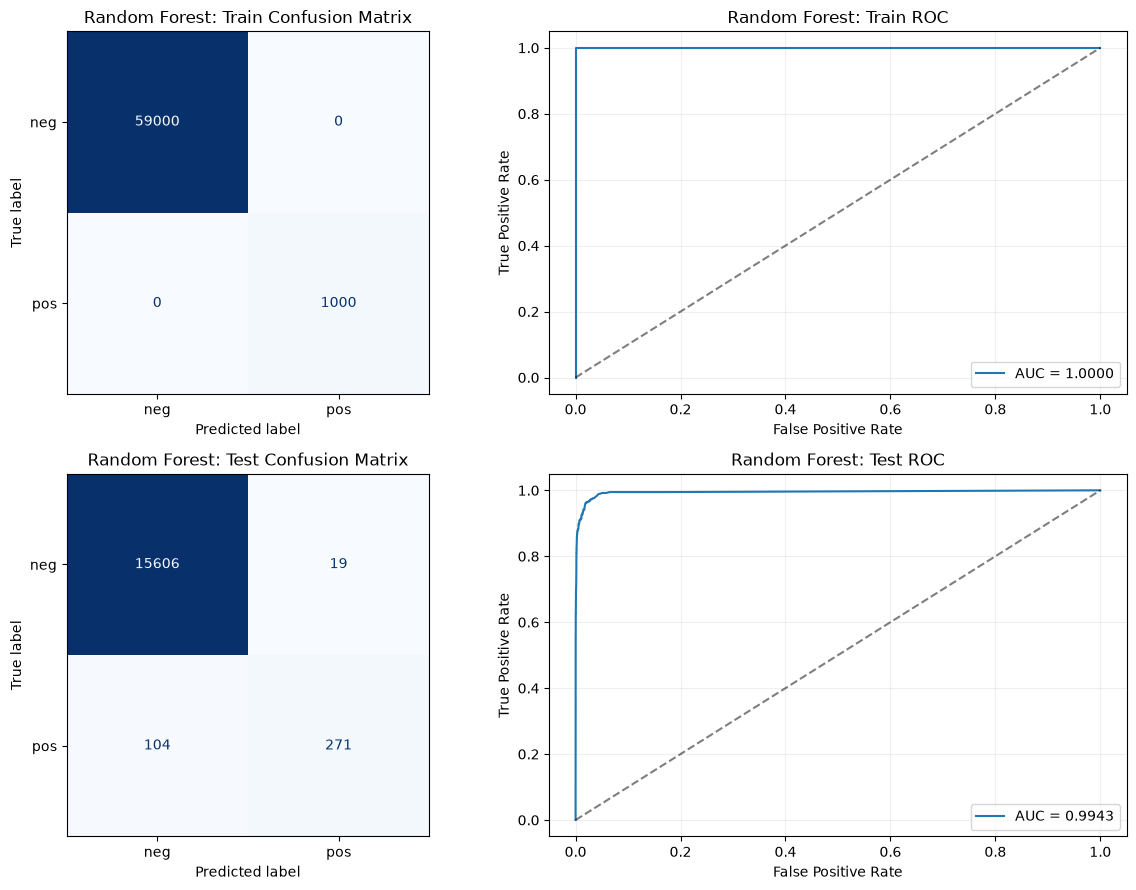

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,1.000000,0.000000,0,1.000000,1.000000
Test,0.992312,0.007687,123,0.722667,0.994306


In [12]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    roc_curve,
    roc_auc_score
)


def evaluate_binary_classifier(
    model,
    model_name,
    X_train_eval,
    y_train_eval,
    X_test_eval,
    y_test_eval
):
    positive_index = np.flatnonzero(
        model.classes_ == 1
    )[0]

    evaluation_sets = [
        ("Train", X_train_eval, y_train_eval),
        ("Test", X_test_eval, y_test_eval)
    ]

    records = []

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 9)
    )

    for row, (split_name, X_eval, y_eval) in enumerate(
        evaluation_sets
    ):
        predictions = model.predict(X_eval)

        probabilities = model.predict_proba(
            X_eval
        )[:, positive_index]

        accuracy = accuracy_score(y_eval, predictions)
        auc = roc_auc_score(y_eval, probabilities)

        cm = confusion_matrix(
            y_eval,
            predictions,
            labels=[0, 1]
        )

        records.append({
            "split": split_name,
            "accuracy": accuracy,
            "error": 1 - accuracy,
            "mistakes": int(
                np.sum(predictions != np.asarray(y_eval))
            ),
            "positive_recall": recall_score(
                y_eval,
                predictions,
                pos_label=1,
                zero_division=0
            ),
            "AUC": auc
        })

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["neg", "pos"]
        ).plot(
            ax=axes[row, 0],
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        axes[row, 0].set_title(
            f"{model_name}: {split_name} Confusion Matrix"
        )

        fpr, tpr, _ = roc_curve(
            y_eval,
            probabilities
        )

        axes[row, 1].plot(
            fpr,
            tpr,
            label=f"AUC = {auc:.4f}"
        )

        axes[row, 1].plot(
            [0, 1],
            [0, 1],
            "k--",
            alpha=0.5
        )

        axes[row, 1].set_xlabel("False Positive Rate")
        axes[row, 1].set_ylabel("True Positive Rate")
        axes[row, 1].set_title(
            f"{model_name}: {split_name} ROC"
        )
        axes[row, 1].legend(loc="lower right")
        axes[row, 1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(records).set_index("split")


rf_plain_results = evaluate_binary_classifier(
    model=rf_plain,
    model_name="Random Forest",
    X_train_eval=X_train,
    y_train_eval=y_train,
    X_test_eval=X_test,
    y_test_eval=y_test
)

display(rf_plain_results.round(6))

In [13]:
rf_plain_oob_error = 1 - rf_plain.oob_score_
rf_plain_test_error = rf_plain_results.loc["Test", "error"]

rf_plain_error_comparison = pd.DataFrame({
    "error": [
        rf_plain_oob_error,
        rf_plain_test_error
    ]
}, index=["OOB", "Test"])

display(rf_plain_error_comparison.round(6))

print(
    "Test error minus OOB error:",
    f"{100 * (rf_plain_test_error - rf_plain_oob_error):+.3f}",
    "percentage points"
)

,error
OOB,0.005817
Test,0.007687


Test error minus OOB error: +0.187 percentage points


The random forest correctly classified all training observations.
Its training error was 0, and its training AUC was 1.00.

On the test set, the accuracy was 99.23%, and the error was 0.7688%.
The model made 123 mistakes: 19 false positives and 104 false negatives.

It correctly identified 271 of the 375 positive observations.
The positive-class recall was 72.27%, and the test AUC was 0.9943.

The OOB error was 0.5817%, which was about 0.187 percentage
points lower than the test error.

The model had high overall accuracy, but it still missed
many positive observations.

### (d) Random Forest with Class Balancing

Common ways to address class imbalance include class weighting,
oversampling, and undersampling.

I use class_weight="balanced_subsample".
For each tree, class weights are calculated from its bootstrap sample.
The minority class receives more weight.

I use this setting so that class balancing is applied within
each tree's sample. I also check that every training observation
has a valid OOB prediction.

I keep the other model settings the same as in part (c).
The test set is unchanged.

Reference:
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [14]:
from sklearn.base import clone

rf_balanced = clone(rf_plain).set_params(
    class_weight="balanced_subsample"
)

start_time = perf_counter()

rf_balanced.fit(X_train, y_train)

elapsed = perf_counter() - start_time

oob_probabilities = rf_balanced.oob_decision_function_

valid_oob = (
    np.isfinite(oob_probabilities).all(axis=1)
    & (oob_probabilities.sum(axis=1) > 0)
)

print(f"Training finished in {elapsed:.2f} seconds.")
print("Class weighting:", rf_balanced.class_weight)
print("Number of trees:", len(rf_balanced.estimators_))
print("Number of input features:", rf_balanced.n_features_in_)

print(
    "Samples without OOB predictions:",
    int((~valid_oob).sum())
)

assert valid_oob.all(), "Some OOB predictions are missing."

print(f"OOB accuracy: {rf_balanced.oob_score_:.6f}")
print(f"OOB error: {1 - rf_balanced.oob_score_:.6f}")

Training finished in 10.88 seconds.
Class weighting: balanced_subsample
Number of trees: 500
Number of input features: 170
Samples without OOB predictions: 0
OOB accuracy: 0.992517
OOB error: 0.007483


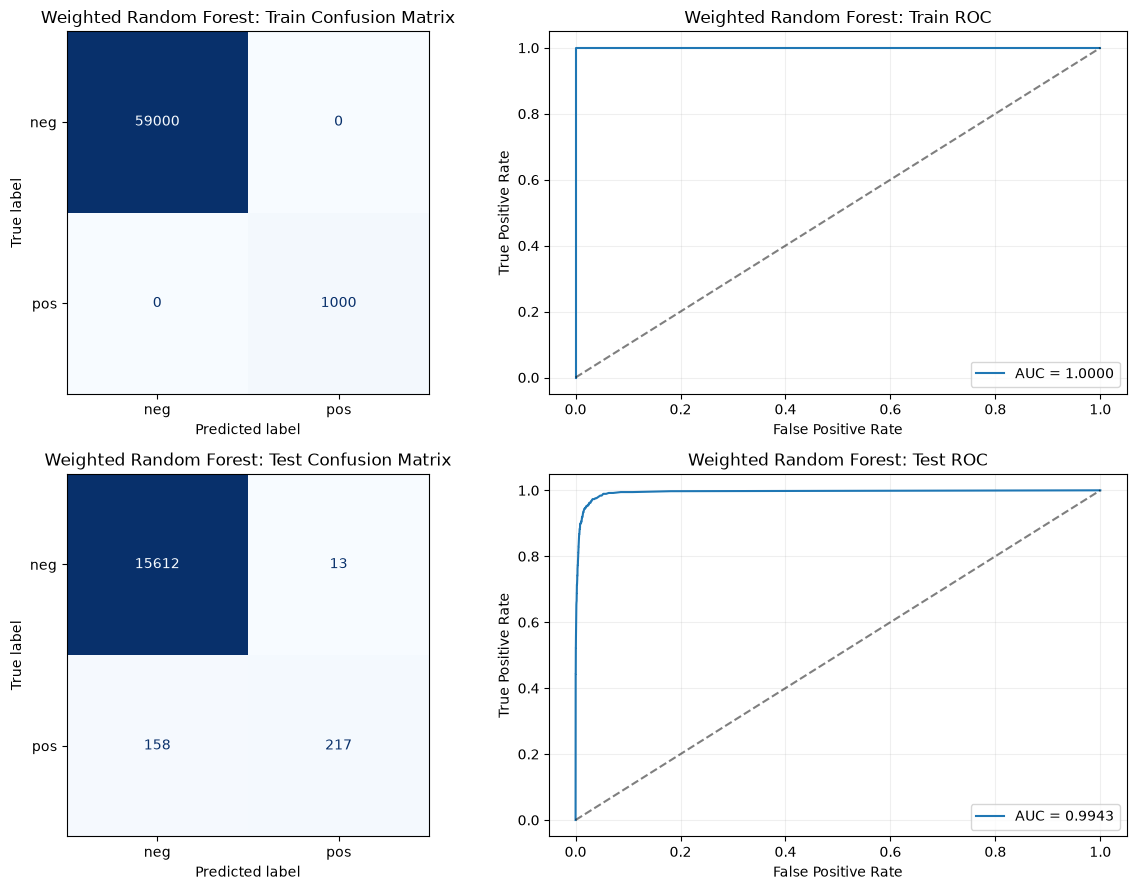

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,1.000000,0.000000,0,1.000000,1.000000
Test,0.989312,0.010687,171,0.578667,0.994308


In [15]:
rf_balanced_results = evaluate_binary_classifier(
    model=rf_balanced,
    model_name="Weighted Random Forest",
    X_train_eval=X_train,
    y_train_eval=y_train,
    X_test_eval=X_test,
    y_test_eval=y_test
)

display(rf_balanced_results.round(6))

In [16]:
rf_balanced_oob_error = 1 - rf_balanced.oob_score_

rf_comparison = pd.DataFrame({
    "training_error": [
        rf_plain_results.loc["Train", "error"],
        rf_balanced_results.loc["Train", "error"]
    ],
    "test_error": [
        rf_plain_results.loc["Test", "error"],
        rf_balanced_results.loc["Test", "error"]
    ],
    "test_mistakes": [
        rf_plain_results.loc["Test", "mistakes"],
        rf_balanced_results.loc["Test", "mistakes"]
    ],
    "test_positive_recall": [
        rf_plain_results.loc["Test", "positive_recall"],
        rf_balanced_results.loc["Test", "positive_recall"]
    ],
    "test_AUC": [
        rf_plain_results.loc["Test", "AUC"],
        rf_balanced_results.loc["Test", "AUC"]
    ],
    "OOB_error": [
        rf_plain_oob_error,
        rf_balanced_oob_error
    ]
}, index=[
    "Random Forest",
    "Weighted Random Forest"
])

rf_comparison["test_minus_OOB"] = (
    rf_comparison["test_error"]
    - rf_comparison["OOB_error"]
)

display(rf_comparison.round(6))

,training_error,test_error,test_mistakes,test_positive_recall,test_AUC,OOB_error,test_minus_OOB
Random Forest,0.0,0.007687,123,0.722667,0.994306,0.005817,0.001871
Weighted Random Forest,0.0,0.010687,171,0.578667,0.994308,0.007483,0.003204


Both random forests correctly classified all training observations.

Class balancing did not improve test performance in this experiment.
The test error increased from 0.7688% to 1.0688%.
The number of test mistakes increased from 123 to 171.

False positives decreased from 19 to 13, but false negatives
increased from 104 to 158. Positive-class recall dropped
from 72.27% to 57.87%.

The test AUC values were almost the same, at about 0.9943.

For the weighted model, the OOB error was 0.7483%.
This was about 0.3204 percentage points below its test error.

The ordinary random forest performed better at the default
classification threshold in this experiment.

### (e) XGBoost with L1 Regularization

Implementation note:
XGBoost's gblinear booster fits a global linear model.
It does not fit a separate logistic regression at each tree node.
I use gblinear with a logistic objective for the L1-penalized
logistic model in this experiment.

I use all 170 features without class balancing.

I use five-fold stratified cross-validation to select alpha,
the L1 regularization strength. I select the value with the
lowest mean validation misclassification rate.

Median imputation and standardization are fitted inside each fold.
The test set is not used to select alpha.

Reference:
https://xgboost.readthedocs.io/en/stable/parameter.html

In [17]:
import xgboost as xgb

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from joblib import parallel_config

print("XGBoost version:", xgb.__version__)

cv_aps = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits_aps = list(
    cv_aps.split(X_train_raw, y_train)
)

alpha_values = np.logspace(-6, 0, 7)

print("Candidate alpha values:")
print(alpha_values)

xgb_plain_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    (
        "xgb",
        xgb.XGBClassifier(
            booster="gblinear",
            objective="binary:logistic",
            reg_lambda=0,
            updater="coord_descent",
            feature_selector="cyclic",
            n_estimators=500,
            learning_rate=0.1,
            n_jobs=1,
            random_state=42,
            eval_metric="logloss",
            verbosity=0
        )
    )
])

XGBoost version: 3.4.1
Candidate alpha values:
[1.e-06 1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00]


In [18]:
xgb_plain_search = GridSearchCV(
    estimator=xgb_plain_pipeline,
    param_grid={
        "xgb__reg_alpha": alpha_values
    },
    scoring="accuracy",
    cv=cv_splits_aps,
    refit=True,
    n_jobs=4,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1
):
    xgb_plain_search.fit(
        X_train_raw,
        y_train
    )

elapsed = perf_counter() - start_time

best_xgb_plain = xgb_plain_search.best_estimator_

best_alpha_xgb_plain = (
    xgb_plain_search.best_params_["xgb__reg_alpha"]
)

best_cv_error_xgb_plain = (
    1 - xgb_plain_search.best_score_
)

xgb_plain_cv_results = pd.DataFrame({
    "alpha": [
        params["xgb__reg_alpha"]
        for params in xgb_plain_search.cv_results_["params"]
    ],
    "CV_accuracy": (
        xgb_plain_search.cv_results_["mean_test_score"]
    ),
    "CV_error": (
        1 - xgb_plain_search.cv_results_["mean_test_score"]
    ),
    "CV_std": (
        xgb_plain_search.cv_results_["std_test_score"]
    )
}).sort_values(
    ["CV_error", "alpha"]
).reset_index(drop=True)

print(f"\nSearch finished in {elapsed:.2f} seconds.")
print("Best alpha:", best_alpha_xgb_plain)

print(
    "Best mean CV accuracy:",
    f"{xgb_plain_search.best_score_:.6f}"
)

print(
    "Best mean CV error:",
    f"{best_cv_error_xgb_plain:.6f}"
)

display(xgb_plain_cv_results)

Fitting 5 folds for each of 7 candidates, totalling 35 fits

Search finished in 256.15 seconds.
Best alpha: 0.01
Best mean CV accuracy: 0.985300
Best mean CV error: 0.014700


,alpha,CV_accuracy,CV_error,CV_std
0,0.010000,0.985300,0.014700,1.062753e-03
1,0.000010,0.983333,0.016667,1.110223e-16
2,0.000100,0.983333,0.016667,1.110223e-16
3,0.001000,0.983333,0.016667,1.110223e-16
4,0.100000,0.983333,0.016667,1.110223e-16
5,1.000000,0.983333,0.016667,1.110223e-16
6,0.000001,0.596667,0.403333,4.735680e-01


#### Cross-Validation Results

The best alpha is 0.01.
The mean five-fold CV accuracy is 98.53%, and the CV error is 1.47%.

Predicting every training observation as negative gives 98.33% accuracy.
The selected model has a slightly higher CV accuracy.
I also check positive recall, the confusion matrix, and AUC.

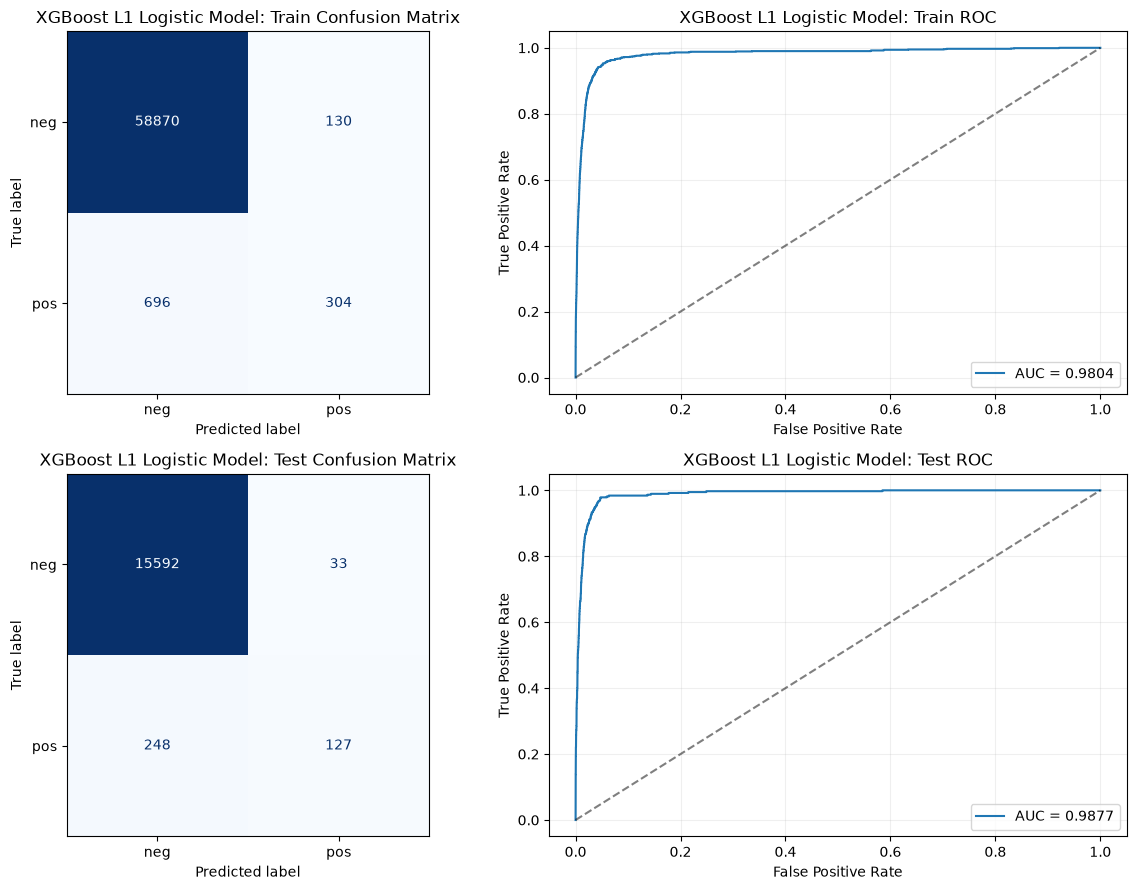

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,0.986233,0.013767,826,0.304000,0.980382
Test,0.982437,0.017563,281,0.338667,0.987661


In [19]:
xgb_plain_results = evaluate_binary_classifier(
    model=best_xgb_plain,
    model_name="XGBoost L1 Logistic Model",
    X_train_eval=X_train_raw,
    y_train_eval=y_train,
    X_test_eval=X_test_raw,
    y_test_eval=y_test
)

display(xgb_plain_results)

In [20]:
xgb_plain_test_error = xgb_plain_results.loc["Test", "error"]

xgb_plain_error_comparison = pd.DataFrame(
    {
        "error": [
            best_cv_error_xgb_plain,
            xgb_plain_test_error
        ]
    },
    index=["Cross-validation", "Test"]
)

xgb_plain_error_comparison["error_percent"] = (
    xgb_plain_error_comparison["error"] * 100
)

display(xgb_plain_error_comparison)

print(
    "Test error minus CV error: "
    f"{100 * (xgb_plain_test_error - best_cv_error_xgb_plain):.4f} "
    "percentage points"
)

,error,error_percent
Cross-validation,0.014700,1.47000
Test,0.017563,1.75625


Test error minus CV error: 0.2862 percentage points


#### Model Results

The training error is 1.3767%, and the test error is 1.7563%.
The test error is about 0.286 percentage points higher than the CV error.

The test AUC is 0.9877.
However, positive recall is only 33.87% at the default classification threshold.
The model correctly finds 127 positive observations and misses 248.
It also labels 33 negative observations as positive.

The ordinary random forest has a lower test error and higher positive recall
than this model.

### (f) SMOTE and XGBoost with L1 Regularization

I use SMOTE to create more positive training observations.

I place median imputation, standardization, SMOTE, and the model
in one pipeline.
During cross-validation, these steps are fitted using only
the training part of each fold.
SMOTE is not applied to the validation part or the test set.

I use the same five folds and alpha values as in part (e).
I select alpha using the lowest mean validation misclassification rate.

Install the packages listed in requirements.txt before running this notebook.

In [21]:
import imblearn
import sklearn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("imbalanced-learn version:", imblearn.__version__)
print("scikit-learn version:", sklearn.__version__)
print("SMOTE imports are ready.")

imbalanced-learn version: 0.14.2
scikit-learn version: 1.9.1
SMOTE imports are ready.


In [22]:
from sklearn.base import clone

xgb_smote_pipeline = ImbPipeline(
    steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        (
            "smote",
            SMOTE(
                sampling_strategy="auto",
                k_neighbors=5,
                random_state=42
            )
        ),
        (
            "xgb",
            clone(xgb_plain_pipeline.named_steps["xgb"])
        )
    ]
)

print("Original training class counts:")
print(y_train.value_counts().sort_index())

print("\nPipeline steps:")
for step_name, step in xgb_smote_pipeline.steps:
    print(f"{step_name}: {type(step).__name__}")

Original training class counts:
class
0    59000
1     1000
Name: count, dtype: int64

Pipeline steps:
impute: SimpleImputer
scale: StandardScaler
smote: SMOTE
xgb: XGBClassifier


In [23]:
xgb_smote_search = GridSearchCV(
    estimator=xgb_smote_pipeline,
    param_grid={
        "xgb__reg_alpha": alpha_values
    },
    scoring="accuracy",
    cv=cv_splits_aps,
    refit=True,
    n_jobs=4,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1
):
    xgb_smote_search.fit(
        X_train_raw,
        y_train
    )

elapsed = perf_counter() - start_time

best_xgb_smote = xgb_smote_search.best_estimator_

best_alpha_xgb_smote = (
    xgb_smote_search.best_params_["xgb__reg_alpha"]
)

best_cv_error_xgb_smote = (
    1 - xgb_smote_search.best_score_
)

xgb_smote_cv_results = pd.DataFrame(
    {
        "alpha": [
            params["xgb__reg_alpha"]
            for params in xgb_smote_search.cv_results_["params"]
        ],
        "CV_accuracy": (
            xgb_smote_search.cv_results_["mean_test_score"]
        ),
        "CV_error": (
            1 - xgb_smote_search.cv_results_["mean_test_score"]
        ),
        "CV_std": (
            xgb_smote_search.cv_results_["std_test_score"]
        )
    }
).sort_values(
    ["CV_error", "alpha"]
).reset_index(drop=True)

print(f"\nSearch finished in {elapsed:.2f} seconds.")
print("Best alpha:", best_alpha_xgb_smote)

print(
    "Best mean CV accuracy: "
    f"{xgb_smote_search.best_score_:.6f}"
)

print(
    "Best mean CV error: "
    f"{best_cv_error_xgb_smote:.6f}"
)

display(xgb_smote_cv_results)

Fitting 5 folds for each of 7 candidates, totalling 35 fits

Search finished in 516.07 seconds.
Best alpha: 1.0
Best mean CV accuracy: 0.977900
Best mean CV error: 0.022100


,alpha,CV_accuracy,CV_error,CV_std
0,1.000000,0.977900,0.022100,0.004479
1,0.001000,0.975833,0.024167,0.000693
2,0.000100,0.975583,0.024417,0.001194
3,0.000001,0.975483,0.024517,0.001005
4,0.000010,0.975383,0.024617,0.001149
5,0.010000,0.970383,0.029617,0.000861
6,0.100000,0.969600,0.030400,0.001114


#### Additional Alpha Search

The first search selects alpha = 1.0.
This is the largest value in the first search range.

I also check alpha values of 3, 10, and 100.
I use the same five folds and select alpha using CV error.
The test set is not used in this search.

In [24]:
xgb_smote_extra_search = clone(xgb_smote_search).set_params(
    param_grid={"xgb__reg_alpha": [3.0, 10.0, 100.0]}
)

start_time = perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1
):
    xgb_smote_extra_search.fit(X_train_raw, y_train)

elapsed = perf_counter() - start_time

extra_results = pd.DataFrame(
    {
        "alpha": [
            params["xgb__reg_alpha"]
            for params in xgb_smote_extra_search.cv_results_["params"]
        ],
        "CV_accuracy": (
            xgb_smote_extra_search.cv_results_["mean_test_score"]
        ),
        "CV_error": (
            1 - xgb_smote_extra_search.cv_results_["mean_test_score"]
        ),
        "CV_std": (
            xgb_smote_extra_search.cv_results_["std_test_score"]
        )
    }
)

xgb_smote_cv_results = pd.concat(
    [xgb_smote_cv_results, extra_results],
    ignore_index=True
).drop_duplicates(
    subset="alpha"
).sort_values(
    ["CV_error", "alpha"]
).reset_index(drop=True)

if xgb_smote_extra_search.best_score_ > xgb_smote_search.best_score_:
    xgb_smote_search = xgb_smote_extra_search

best_xgb_smote = xgb_smote_search.best_estimator_
best_alpha_xgb_smote = (
    xgb_smote_search.best_params_["xgb__reg_alpha"]
)
best_cv_error_xgb_smote = 1 - xgb_smote_search.best_score_

print(f"Additional search finished in {elapsed:.2f} seconds.")
print("Best alpha across both searches:", best_alpha_xgb_smote)
print(f"Best mean CV error: {best_cv_error_xgb_smote:.6f}")

display(xgb_smote_cv_results)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Additional search finished in 221.54 seconds.
Best alpha across both searches: 3.0
Best mean CV error: 0.016667


,alpha,CV_accuracy,CV_error,CV_std
0,3.000000,0.983333,0.016667,1.110223e-16
1,10.000000,0.983333,0.016667,1.110223e-16
2,100.000000,0.983333,0.016667,1.110223e-16
3,1.000000,0.977900,0.022100,4.478777e-03
4,0.001000,0.975833,0.024167,6.932211e-04
5,0.000100,0.975583,0.024417,1.193734e-03
6,0.000001,0.975483,0.024517,1.004711e-03
7,0.000010,0.975383,0.024617,1.149396e-03
8,0.010000,0.970383,0.029617,8.605554e-04
9,0.100000,0.969600,0.030400,1.113553e-03


#### Final Cross-Validation Results

Alpha values of 3, 10, and 100 have the same mean CV error of 1.6667%.
I select the smallest tied value, alpha = 3.

The CV accuracy equals the accuracy of predicting every observation as negative.
I check the model coefficients and predictions to see whether
the model still finds positive observations.

In [25]:
smote_coefficients = np.asarray(
    best_xgb_smote.named_steps["xgb"].coef_
).ravel()

print("Number of coefficients:", smote_coefficients.size)
print(
    "Number of nonzero coefficients:",
    np.count_nonzero(smote_coefficients)
)

smote_train_predictions = best_xgb_smote.predict(X_train_raw)

print("\nPredicted class counts on the original training set:")

display(
    pd.Series(smote_train_predictions)
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Predicted class")
    .to_frame("count")
)

Number of coefficients: 170
Number of nonzero coefficients: 0


C:\Users\19098\DSCI-552\.venv\Lib\site-packages\xgboost\sklearn.py:1695: UserWarning: [03:51:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  coef = np.array(json.loads(b.get_dump(dump_format="json")[0])["weight"])



Predicted class counts on the original training set:


,count
Predicted class,
0,60000
1,0


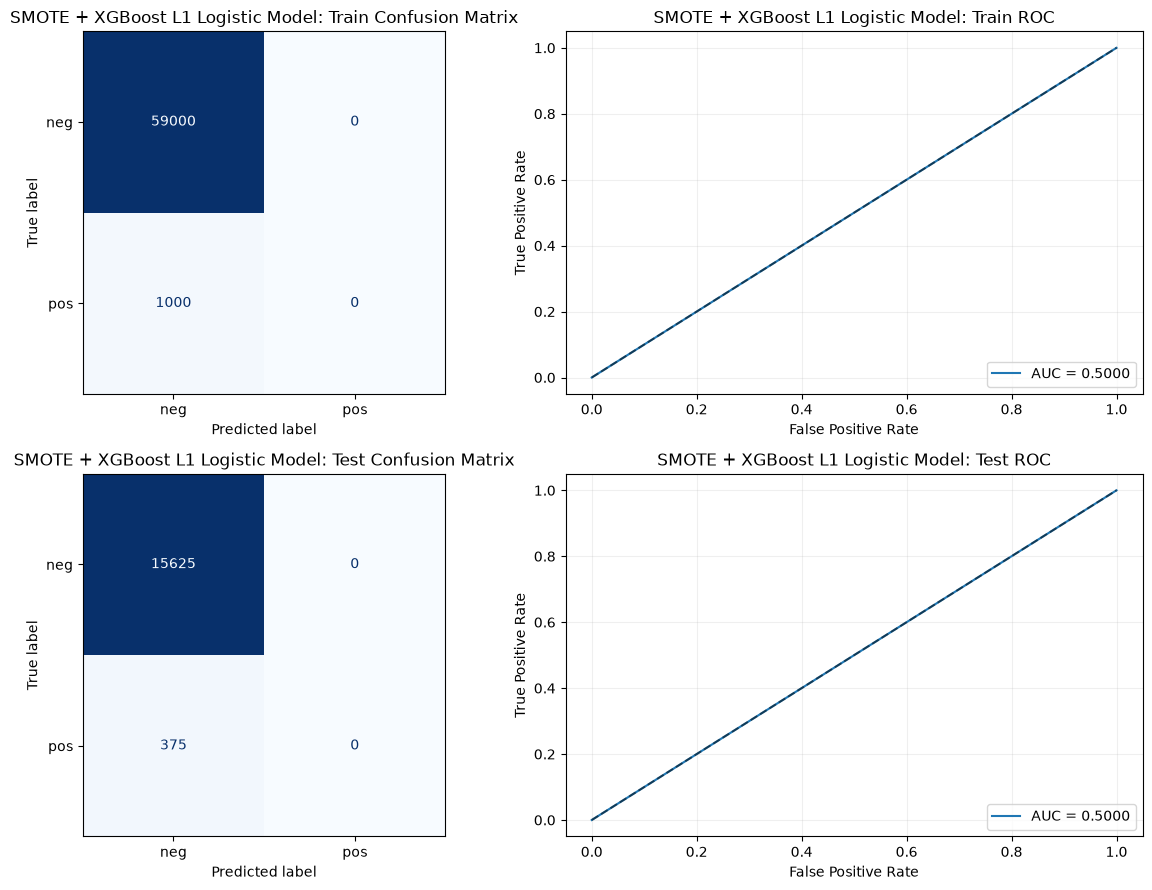

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,0.983333,0.016667,1000,0.0,0.5
Test,0.976562,0.023438,375,0.0,0.5


In [26]:
xgb_smote_results = evaluate_binary_classifier(
    model=best_xgb_smote,
    model_name="SMOTE + XGBoost L1 Logistic Model",
    X_train_eval=X_train_raw,
    y_train_eval=y_train,
    X_test_eval=X_test_raw,
    y_test_eval=y_test
)

display(xgb_smote_results)

#### SMOTE Model Results

The selected alpha is 3.
All 170 feature coefficients are zero.
The model predicts every observation as negative.

The training error is 1.6667%, and the test error is 2.34375%.
The test error is about 0.6771 percentage points higher than the CV error.

Positive recall is 0%, and AUC is 0.5 on both sets.
The model misses all 375 positive test observations.

The CV search uses misclassification rate.
Since most validation observations are negative, predicting only the
negative class gives a low error rate.

With this model and selection rule, SMOTE does not improve test performance.
This result does not mean that SMOTE always performs poorly.

This experiment uses the global gblinear model described in part (e).

In [27]:
model_test_comparison = pd.DataFrame(
    {
        "Random forest": rf_plain_results.loc["Test"],
        "Weighted random forest": rf_balanced_results.loc["Test"],
        "XGBoost L1": xgb_plain_results.loc["Test"],
        "SMOTE + XGBoost L1": xgb_smote_results.loc["Test"]
    }
).T

model_test_comparison["test_error_percent"] = (
    100 * model_test_comparison["error"]
)

model_test_comparison["positive_recall_percent"] = (
    100 * model_test_comparison["positive_recall"]
)

model_test_comparison["mistakes"] = (
    model_test_comparison["mistakes"].astype(int)
)

display(
    model_test_comparison[
        [
            "test_error_percent",
            "mistakes",
            "positive_recall_percent",
            "AUC"
        ]
    ]
)

,test_error_percent,mistakes,positive_recall_percent,AUC
Random forest,0.76875,123,72.266667,0.994306
Weighted random forest,1.06875,171,57.866667,0.994308
XGBoost L1,1.75625,281,33.866667,0.987661
SMOTE + XGBoost L1,2.34375,375,0.000000,0.500000


In [28]:
cv_test_comparison = pd.DataFrame(
    {
        "CV_error_percent": [
            100 * best_cv_error_xgb_plain,
            100 * best_cv_error_xgb_smote
        ],
        "test_error_percent": [
            100 * xgb_plain_results.loc["Test", "error"],
            100 * xgb_smote_results.loc["Test", "error"]
        ]
    },
    index=["XGBoost L1", "SMOTE + XGBoost L1"]
)

cv_test_comparison["test_minus_CV_percentage_points"] = (
    cv_test_comparison["test_error_percent"]
    - cv_test_comparison["CV_error_percent"]
)

display(cv_test_comparison.round(4))

,CV_error_percent,test_error_percent,test_minus_CV_percentage_points
XGBoost L1,1.4700,1.7563,0.2862
SMOTE + XGBoost L1,1.6667,2.3438,0.6771


#### Model Comparison

The ordinary random forest has the lowest test error, 0.76875%.
It also has the highest positive recall among these four fitted models,
about 72.27%.

The weighted random forest has a higher test error and lower positive recall
than the ordinary random forest.
Their test AUC values are nearly the same.

The XGBoost L1 model without SMOTE performs better than the selected
SMOTE model.
The selected SMOTE model predicts only the negative class and has no
ability to rank positive observations above negative observations.

### Additional XGBoost Tree Experiments

The experiments above use gblinear, which fits a global linear model.

Here, I also fit boosted trees using gbtree.
I use a binary logistic objective and L1 regularization on leaf weights.
Standard gbtree does not fit a separate logistic regression at each node.

I first fit the tree model without class balancing.
I use the same five folds to select alpha.
The test set is not used to select alpha.

In [29]:
tree_alpha_values = [0.0, 0.01, 0.1, 1.0, 10.0]

xgb_tree_plain_pipeline = Pipeline(
    steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        (
            "xgb",
            xgb.XGBClassifier(
                booster="gbtree",
                objective="binary:logistic",
                tree_method="hist",
                n_estimators=300,
                max_depth=3,
                learning_rate=0.05,
                reg_lambda=0,
                scale_pos_weight=1,
                subsample=1.0,
                colsample_bytree=1.0,
                n_jobs=1,
                random_state=42,
                eval_metric="logloss",
                verbosity=0
            )
        )
    ]
)

xgb_tree_plain_search = GridSearchCV(
    estimator=xgb_tree_plain_pipeline,
    param_grid={"xgb__reg_alpha": tree_alpha_values},
    scoring="accuracy",
    cv=cv_splits_aps,
    refit=True,
    n_jobs=4,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1
):
    xgb_tree_plain_search.fit(X_train_raw, y_train)

elapsed = perf_counter() - start_time

best_xgb_tree_plain = xgb_tree_plain_search.best_estimator_
best_cv_error_xgb_tree_plain = (
    1 - xgb_tree_plain_search.best_score_
)

xgb_tree_plain_cv_results = pd.DataFrame(
    {
        "alpha": [
            params["xgb__reg_alpha"]
            for params in xgb_tree_plain_search.cv_results_["params"]
        ],
        "CV_error": (
            1 - xgb_tree_plain_search.cv_results_["mean_test_score"]
        ),
        "CV_std": (
            xgb_tree_plain_search.cv_results_["std_test_score"]
        )
    }
).sort_values(
    ["CV_error", "alpha"]
).reset_index(drop=True)

print(f"Search finished in {elapsed:.2f} seconds.")
print(
    "Best alpha:",
    xgb_tree_plain_search.best_params_["xgb__reg_alpha"]
)
print(f"Best mean CV error: {best_cv_error_xgb_tree_plain:.6f}")

display(xgb_tree_plain_cv_results)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Search finished in 33.85 seconds.
Best alpha: 0.1
Best mean CV error: 0.006050


,alpha,CV_error,CV_std
0,0.10,0.006050,0.000496
1,1.00,0.006133,0.000430
2,0.01,0.006150,0.000549
3,0.00,0.006250,0.000545
4,10.00,0.006867,0.000400


#### XGBoost Trees Without Class Balancing

The selected alpha is 0.1.
The mean five-fold CV error is 0.6050%.

I evaluate the fitted model on the original training and test sets.

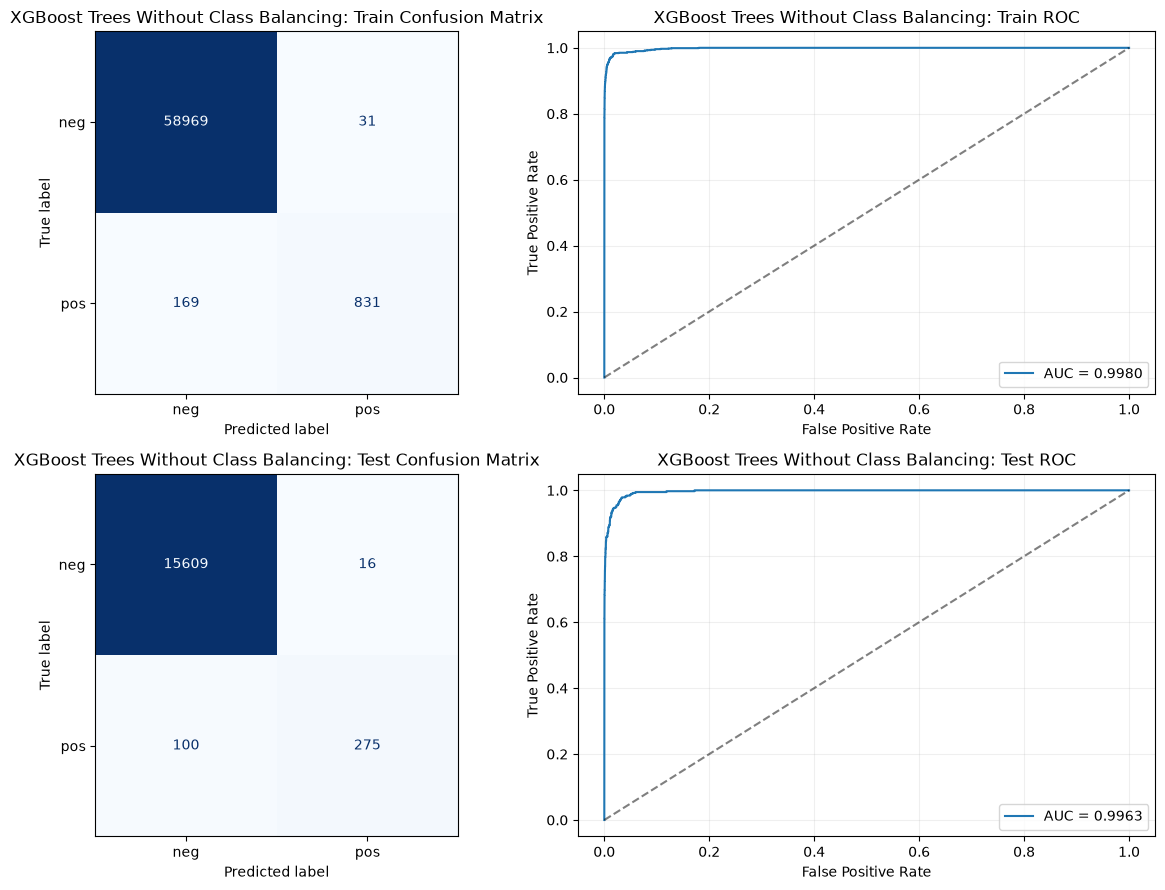

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,0.996667,0.003333,200,0.831000,0.997967
Test,0.992750,0.007250,116,0.733333,0.996273


,error_percent
Cross-validation,0.605
Test,0.725


In [30]:
xgb_tree_plain_results = evaluate_binary_classifier(
    model=best_xgb_tree_plain,
    model_name="XGBoost Trees Without Class Balancing",
    X_train_eval=X_train_raw,
    y_train_eval=y_train,
    X_test_eval=X_test_raw,
    y_test_eval=y_test
)

display(xgb_tree_plain_results)

tree_plain_error_comparison = pd.DataFrame(
    {
        "error_percent": [
            100 * best_cv_error_xgb_tree_plain,
            100 * xgb_tree_plain_results.loc["Test", "error"]
        ]
    },
    index=["Cross-validation", "Test"]
)

display(tree_plain_error_comparison)

#### XGBoost Trees with SMOTE

I keep the same tree settings, alpha values, and five folds.
I add SMOTE inside the pipeline and select alpha again using CV error.

Median imputation, standardization, and SMOTE are fitted using only
the training part of each fold.
The validation parts and the test set keep their original observations.
I use the full training set without undersampling.

In [31]:
xgb_tree_smote_pipeline = ImbPipeline(
    steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        (
            "smote",
            SMOTE(
                sampling_strategy="auto",
                k_neighbors=5,
                random_state=42
            )
        ),
        (
            "xgb",
            clone(xgb_tree_plain_pipeline.named_steps["xgb"])
        )
    ]
)

xgb_tree_smote_search = clone(
    xgb_tree_plain_search
).set_params(
    estimator=xgb_tree_smote_pipeline
)

start_time = perf_counter()

with parallel_config(
    backend="loky",
    inner_max_num_threads=1
):
    xgb_tree_smote_search.fit(X_train_raw, y_train)

elapsed = perf_counter() - start_time

best_xgb_tree_smote = xgb_tree_smote_search.best_estimator_
best_cv_error_xgb_tree_smote = (
    1 - xgb_tree_smote_search.best_score_
)

xgb_tree_smote_cv_results = pd.DataFrame(
    {
        "alpha": [
            params["xgb__reg_alpha"]
            for params in xgb_tree_smote_search.cv_results_["params"]
        ],
        "CV_error": (
            1 - xgb_tree_smote_search.cv_results_["mean_test_score"]
        ),
        "CV_std": (
            xgb_tree_smote_search.cv_results_["std_test_score"]
        )
    }
).sort_values(
    ["CV_error", "alpha"]
).reset_index(drop=True)

print(f"Search finished in {elapsed:.2f} seconds.")
print(
    "Best alpha:",
    xgb_tree_smote_search.best_params_["xgb__reg_alpha"]
)
print(f"Best mean CV error: {best_cv_error_xgb_tree_smote:.6f}")

display(xgb_tree_smote_cv_results)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Search finished in 66.45 seconds.
Best alpha: 0.0
Best mean CV error: 0.017483


,alpha,CV_error,CV_std
0,0.00,0.017483,0.001295
1,0.01,0.017517,0.000980
2,0.10,0.017617,0.001119
3,1.00,0.017733,0.000999
4,10.00,0.018200,0.001381


#### Tree Model Results Without SMOTE

The training error is 0.3333%, and the test error is 0.7250%.
The test error is 0.1200 percentage points higher than the CV error.

The model makes 116 test mistakes.
It correctly finds 275 positive observations and misses 100.
It also labels 16 negative observations as positive.

Test positive recall is 73.33%, and test AUC is 0.9963.

#### SMOTE Cross-Validation Results

The selected alpha is 0.
This means the selected tree model has no L1 penalty.
Its mean five-fold CV error is 1.7483%.

I now check its test error, positive recall, and AUC.

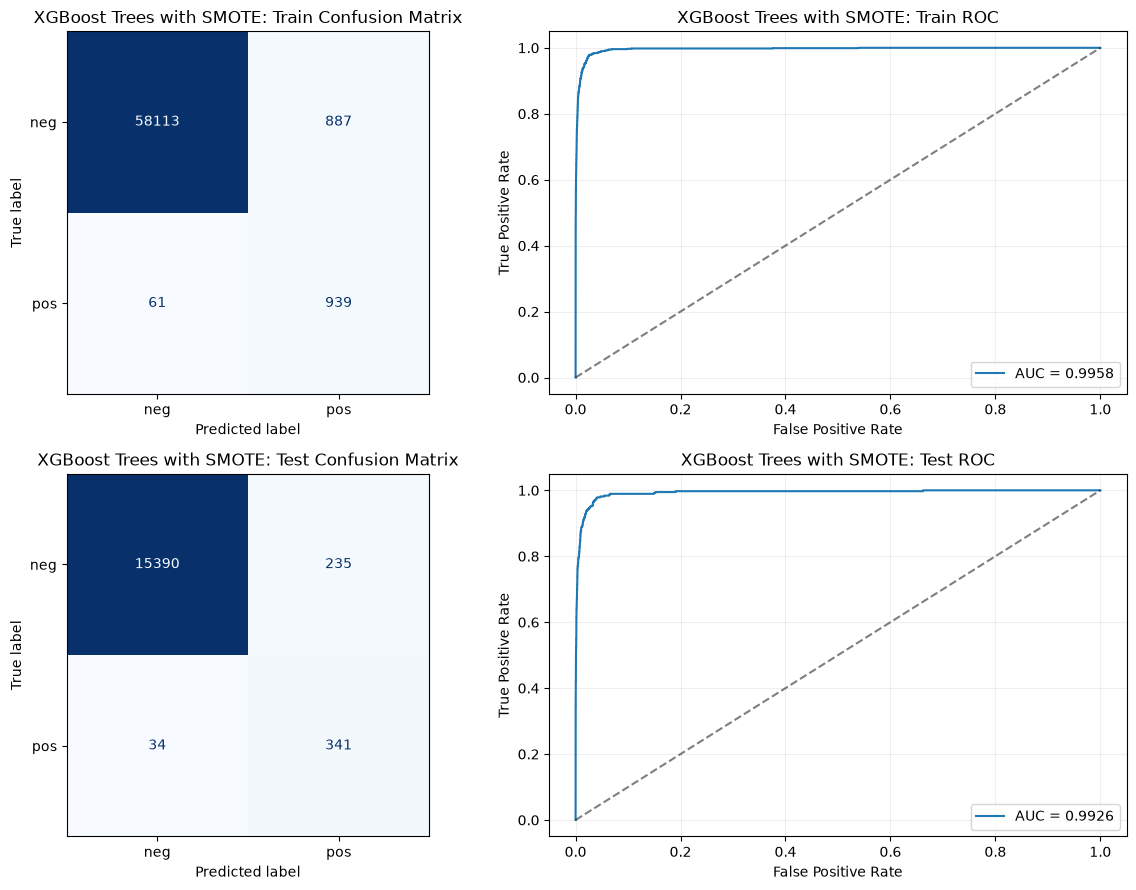

,accuracy,error,mistakes,positive_recall,AUC
split,,,,,
Train,0.984200,0.015800,948,0.939000,0.995781
Test,0.983187,0.016813,269,0.909333,0.992613


In [32]:
xgb_tree_smote_results = evaluate_binary_classifier(
    model=best_xgb_tree_smote,
    model_name="XGBoost Trees with SMOTE",
    X_train_eval=X_train_raw,
    y_train_eval=y_train,
    X_test_eval=X_test_raw,
    y_test_eval=y_test
)

display(xgb_tree_smote_results)

In [33]:
tree_model_comparison = pd.DataFrame(
    {
        "Without SMOTE": xgb_tree_plain_results.loc["Test"],
        "With SMOTE": xgb_tree_smote_results.loc["Test"]
    }
).T

tree_model_comparison["alpha"] = [
    xgb_tree_plain_search.best_params_["xgb__reg_alpha"],
    xgb_tree_smote_search.best_params_["xgb__reg_alpha"]
]

tree_model_comparison["CV_error_percent"] = [
    100 * best_cv_error_xgb_tree_plain,
    100 * best_cv_error_xgb_tree_smote
]

tree_model_comparison["test_error_percent"] = (
    100 * tree_model_comparison["error"]
)

tree_model_comparison["test_positive_recall_percent"] = (
    100 * tree_model_comparison["positive_recall"]
)

tree_model_comparison["test_minus_CV_percentage_points"] = (
    tree_model_comparison["test_error_percent"]
    - tree_model_comparison["CV_error_percent"]
)

tree_model_comparison["mistakes"] = (
    tree_model_comparison["mistakes"].astype(int)
)

display(
    tree_model_comparison[
        [
            "alpha",
            "CV_error_percent",
            "test_error_percent",
            "test_minus_CV_percentage_points",
            "mistakes",
            "test_positive_recall_percent",
            "AUC"
        ]
    ].round(6)
)

,alpha,CV_error_percent,test_error_percent,test_minus_CV_percentage_points,mistakes,test_positive_recall_percent,AUC
Without SMOTE,0.1,0.605000,0.72500,0.120000,116,73.333333,0.996273
With SMOTE,0.0,1.748333,1.68125,-0.067083,269,90.933333,0.992613


#### Comparison of the Tree Models

Without SMOTE, the training error is 0.3333% and the test error is 0.7250%.

With SMOTE, the training error is 1.5800% and the test error is 1.68125%.
The SMOTE test error is about 0.0671 percentage points below its CV error.

SMOTE increases test positive recall from 73.33% to 90.93%.
False negatives decrease from 100 to 34.
However, false positives increase from 16 to 235.

The total number of test mistakes increases from 116 to 269.
Test AUC decreases from 0.9963 to 0.9926.

For these boosted tree models, SMOTE helps find more positive observations,
but it also produces more false alarms.
The model without SMOTE has lower test error and higher AUC.

The selected SMOTE alpha is 0, so that fitted model has no L1 penalty.

## 2. ISLR 6.6.3

The Lasso constraint is

$$
\sum_{j=1}^{p}|\beta_j| \leq s.
$$

When $s=0$, all feature coefficients must be zero.
As $s$ increases, the constraint becomes weaker and the model becomes more flexible.

### (a) Training RSS

Answer: (iv).

Training RSS decreases or stays the same.
A larger $s$ allows more possible coefficient values.
The previous solution is still allowed, so the minimum training RSS cannot increase.
It becomes constant once a least squares solution is allowed.

### (b) Test RSS

Answer: (ii).

Test RSS typically decreases at first and then increases.
At small $s$, the model may underfit.
Increasing $s$ can improve the fit.
However, too much flexibility may cause overfitting.

### (c) Variance

Answer: (iii).

Variance generally increases.
With a weaker constraint, the fitted model can change more
when the training data change.

### (d) Squared Bias

Answer: (iv).

Squared bias generally decreases.
A weaker constraint allows the model to fit the true relationship
more closely.

### (e) Irreducible Error

Answer: (v).

Irreducible error stays constant.
It comes from noise in the data.
Changing $s$ does not change this noise.

## 3. ISLR 6.6.5

The two predictors are identical, and the data are centered.
Therefore, the intercept is zero.

Let

$$
x=x_{11}=x_{12}, \qquad x_{21}=x_{22}=-x,
$$

and

$$
y=y_1, \qquad y_2=-y.
$$

The predictions depend only on the sum $\beta_1+\beta_2$.
Assume $\lambda>0$.

### (a) Ridge Optimization Problem

The ridge problem is

$$
\min_{\beta_1,\beta_2}
\left[
2\left(y-x(\beta_1+\beta_2)\right)^2
+\lambda(\beta_1^2+\beta_2^2)
\right].
$$

The first term is RSS.
The second term is the L2 penalty.

### (b) Why the Ridge Coefficients Are Equal

Let $u=\beta_1+\beta_2$.
Setting the two partial derivatives to zero gives

$$
-4x(y-xu)+2\lambda\beta_1=0,
$$

$$
-4x(y-xu)+2\lambda\beta_2=0.
$$

Subtracting these equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Since $\lambda>0$,

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

For a fixed coefficient sum, equal coefficients give the smallest
sum of squares.

### (c) Lasso Optimization Problem

The lasso problem is

$$
\min_{\beta_1,\beta_2}
\left[
2\left(y-x(\beta_1+\beta_2)\right)^2
+\lambda(|\beta_1|+|\beta_2|)
\right].
$$

The penalty now uses absolute values.

### (d) Why the Lasso Can Have Multiple Solutions

For a fixed sum $u=\beta_1+\beta_2$,

$$
|\beta_1|+|\beta_2|\geq |u|.
$$

Equality holds when the coefficients have the same sign,
including cases where one coefficient is zero.

Let $u^*$ be the optimal coefficient sum.
If $u^*\neq 0$, all pairs

$$
\hat{\beta}_1=t u^*,
\qquad
\hat{\beta}_2=(1-t)u^*,
\qquad 0\leq t\leq 1
$$

give the same predictions and the same L1 penalty.
Therefore, they give the same minimum objective value.
There are infinitely many such pairs.

For example, if $u^*=2$, the pairs $(2,0)$, $(1,1)$,
and $(0,2)$ are all solutions.

If the penalty is strong enough that $u^*=0$,
the only solution is $(0,0)$.
Thus, multiple solutions occur when the optimal sum is nonzero.

## 4. ISLR 8.4.5

The ten estimated probabilities of Red are:

0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75.

### Majority Vote

Each tree predicts Red if its estimated probability of Red is above 0.5.
Otherwise, it predicts Green.

Six trees predict Red, and four trees predict Green.
Therefore, the majority vote predicts **Red**.

### Average Probability

The average estimated probability of Red is

$$
\bar{p}_{Red}
=
\frac{
0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75
}{10}
=
\frac{4.5}{10}
=
0.45.
$$

The average estimated probability of Green is

$$
\bar{p}_{Green}=1-0.45=0.55.
$$

Therefore, averaging the probabilities predicts **Green**.

### Why the Results Differ

Majority vote gives each tree one vote.
It does not consider how far each probability is from 0.5.

Averaging uses the probability values.
The four low Red probabilities pull the average below 0.5.
Therefore, the two methods give different predictions.

## 5. ISLR 9.7.3

### (a) Plot the Observations

The plot below shows the seven observations.
Red and Blue points show the two classes.
The numbers identify the observations.

### (b) Optimal Separating Hyperplane

The optimal separating hyperplane is

$$
X_2=X_1-0.5,
$$

or

$$
0.5-X_1+X_2=0.
$$

It lies halfway between the closest edges of the two classes.

### (c) Classification Rule

Use

$$
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1.
$$

Classify an observation as Red if

$$
0.5-X_1+X_2>0.
$$

Otherwise, classify it as Blue.

### (d) Margin

The two margin boundaries are

$$
X_2=X_1
\qquad\text{and}\qquad
X_2=X_1-1.
$$

The margin is the perpendicular distance from the separating
hyperplane to the nearest observations:

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}
\approx 0.3536.
$$

The full width between the margin boundaries is

$$
2M=\frac{1}{\sqrt{2}}\approx 0.7071.
$$

### (e) Support Vectors

The support vectors are observations 2, 3, 5, and 6:

- Red: observation 2 at $(2,2)$ and observation 3 at $(4,4)$.
- Blue: observation 5 at $(2,1)$ and observation 6 at $(4,3)$.

These observations lie on the margin boundaries.
Black circles mark them in the plot.

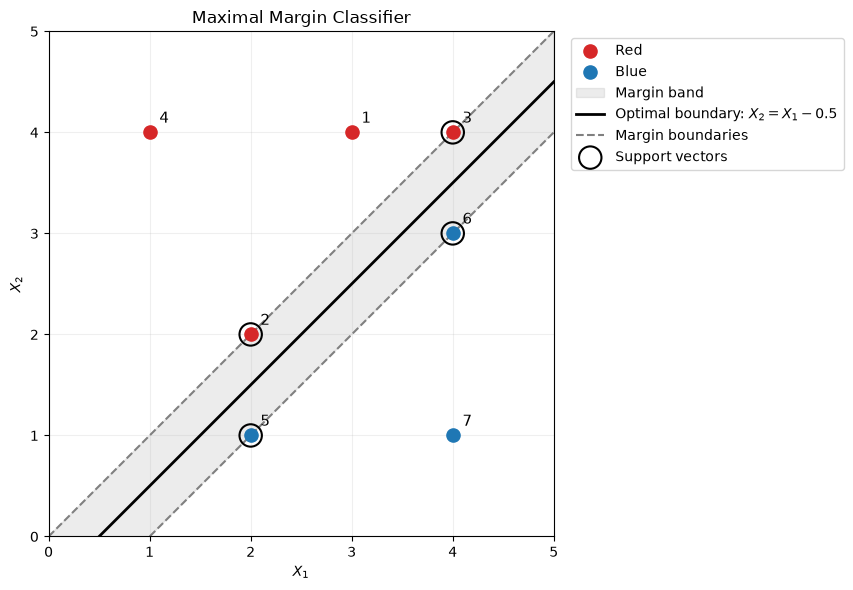

Margin M: 0.3536
Full margin width 2M: 0.7071


In [34]:
toy_svm_data = pd.DataFrame(
    {
        "Observation": [1, 2, 3, 4, 5, 6, 7],
        "X1": [3, 2, 4, 1, 2, 4, 4],
        "X2": [4, 2, 4, 4, 1, 3, 1],
        "Class": [
            "Red", "Red", "Red", "Red",
            "Blue", "Blue", "Blue"
        ]
    }
).set_index("Observation")


def plot_toy_observations(ax, data):
    colors = {"Red": "tab:red", "Blue": "tab:blue"}

    for class_name, color in colors.items():
        points = data[data["Class"] == class_name]

        ax.scatter(
            points["X1"],
            points["X2"],
            color=color,
            s=90,
            label=class_name,
            zorder=3
        )

    for observation, row in data.iterrows():
        ax.annotate(
            str(observation),
            (row["X1"], row["X2"]),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=11
        )

    ax.set(
        xlabel="$X_1$",
        ylabel="$X_2$",
        xlim=(0, 5),
        ylim=(0, 5)
    )
    ax.set_xticks(range(6))
    ax.set_yticks(range(6))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)


fig, ax = plt.subplots(figsize=(9, 6))

plot_toy_observations(ax, toy_svm_data)

x_values = np.linspace(0, 5, 300)

ax.fill_between(
    x_values,
    x_values - 1,
    x_values,
    color="gray",
    alpha=0.15,
    label="Margin band",
    zorder=0
)

ax.plot(
    x_values,
    x_values - 0.5,
    color="black",
    linewidth=2,
    label=r"Optimal boundary: $X_2=X_1-0.5$"
)

ax.plot(
    x_values,
    x_values,
    color="gray",
    linestyle="--",
    label="Margin boundaries"
)

ax.plot(
    x_values,
    x_values - 1,
    color="gray",
    linestyle="--"
)

support_observations = toy_svm_data.loc[[2, 3, 5, 6]]

ax.scatter(
    support_observations["X1"],
    support_observations["X2"],
    s=260,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support vectors",
    zorder=4
)

ax.set_title("Maximal Margin Classifier")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

print(f"Margin M: {1 / (2 * np.sqrt(2)):.4f}")
print(f"Full margin width 2M: {1 / np.sqrt(2):.4f}")

### (f) Moving Observation 7

Observation 7 is at $(4,1)$.
It is far from the separating hyperplane and is not a support vector.

A small movement will not change the maximal margin hyperplane,
as long as the point stays beyond the Blue margin boundary:

$$
X_2<X_1-1.
$$

For example, moving it to $(4.1,1.1)$ keeps it in this region.
The original support vectors still determine the same hyperplane.

### (g) A Non-Optimal Separating Hyperplane

One example is

$$
X_2=X_1-0.25,
$$

or

$$
0.25-X_1+X_2=0.
$$

This line correctly separates all seven observations.
However, its minimum distance to the observations is

$$
\frac{0.25}{\sqrt{2}}\approx 0.1768.
$$

This is smaller than the maximum margin of about 0.3536.
Therefore, this separating hyperplane is not optimal.

### (h) Adding an Observation

Add a Blue observation at $(2,3)$.

This point lies inside the region formed by the Red observations.
In particular,

$$
(2,3)
=
0.5(2,2)+0.25(3,4)+0.25(1,4).
$$

All three points on the right are Red.
Any straight line that puts these Red points on one side
must also put their weighted average on that side.

Therefore, no straight line can separate all Red and Blue observations
after adding this Blue point.

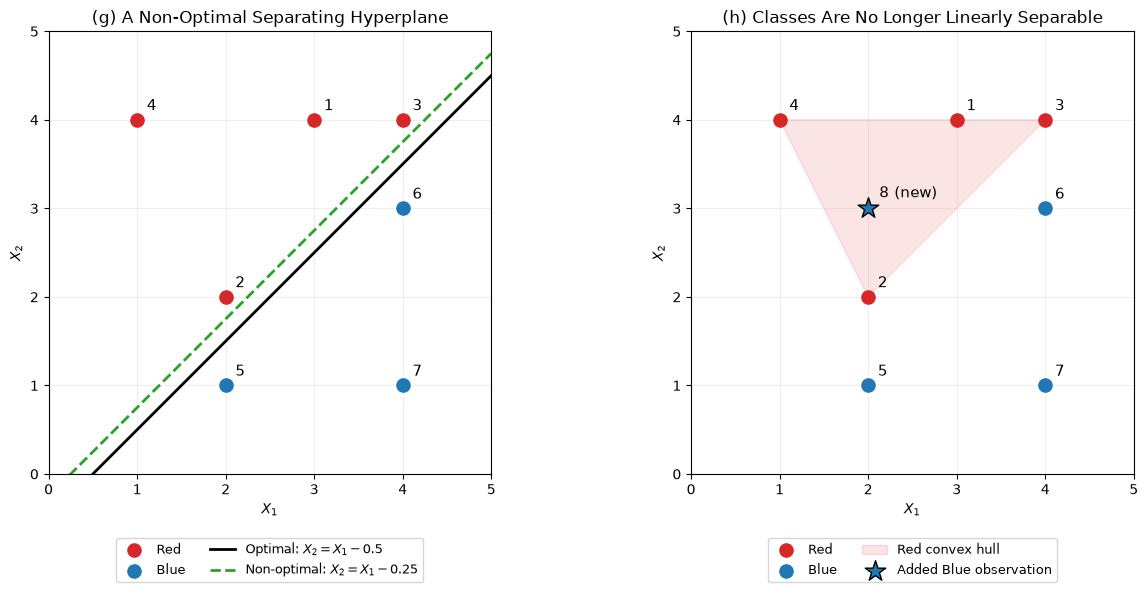

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

toy_line_x = np.linspace(0, 5, 300)

plot_toy_observations(axes[0], toy_svm_data)

axes[0].plot(
    toy_line_x,
    toy_line_x - 0.5,
    color="black",
    linewidth=2,
    label=r"Optimal: $X_2=X_1-0.5$"
)

axes[0].plot(
    toy_line_x,
    toy_line_x - 0.25,
    color="tab:green",
    linestyle="--",
    linewidth=2,
    label=r"Non-optimal: $X_2=X_1-0.25$"
)

axes[0].set_title("(g) A Non-Optimal Separating Hyperplane")

plot_toy_observations(axes[1], toy_svm_data)

red_hull = toy_svm_data.loc[[4, 2, 3]]

axes[1].fill(
    red_hull["X1"],
    red_hull["X2"],
    color="tab:red",
    alpha=0.12,
    label="Red convex hull",
    zorder=0
)

axes[1].scatter(
    2,
    3,
    color="tab:blue",
    marker="*",
    s=240,
    edgecolors="black",
    label="Added Blue observation",
    zorder=5
)

axes[1].annotate(
    "8 (new)",
    (2, 3),
    xytext=(8, 8),
    textcoords="offset points",
    fontsize=11
)

axes[1].set_title("(h) Classes Are No Longer Linearly Separable")

for ax in axes:
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncol=2,
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [36]:
from pathlib import Path

data_dir = Path("data")

data_files = [
    "aps_failure_training_set.csv",
    "aps_failure_test_set.csv"
]

missing_files = [
    filename
    for filename in data_files
    if not (data_dir / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Put the APS CSV files in the data folder. Missing files: "
        + ", ".join(missing_files)
    )

print("Working directory:", Path.cwd())
print("Data folder:", data_dir.resolve())

for filename in data_files:
    print(filename, "exists:", (data_dir / filename).is_file())

Working directory: C:\Users\19098\DSCI-552\Homework6
Data folder: C:\Users\19098\DSCI-552\Homework6\data
aps_failure_training_set.csv exists: True
aps_failure_test_set.csv exists: True
